In [1]:
%pip install -qq pandas matplotlib scipy
import matplotlib.pylab as plt
# test 1

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
datafile=pd.read_csv ("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/sleep.csv")
datafile.groupby('group').describe()

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
source=pd.read_csv ("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/Income2023.csv")
# Aggregate at each observed income value for a readable reproduction of the fitted relationships.
figure_2 = (source.groupby(['income_above_100','income','log_income'], as_index=False)
            .agg(mean_wellbeing=('wellbeing','mean'), n=('wellbeing','size')))
figure_2['income_group'] = np.where(figure_2['income_above_100'].eq(1), '$100,000 and above', 'Below $100,000')
figure_2 = figure_2.sort_values(['income_group','log_income'])
plt.figure(figsize=(6, 4))
plt.plot(figure_2.query("income_group == '$100,000 and above'")['log_income'],
         figure_2.query("income_group == '$100,000 and above'")['mean_wellbeing'], label='$100,000 and above', color='blue')
plt.plot(figure_2.query("income_group == 'Below $100,000'")['log_income'],
         figure_2.query("income_group == 'Below $100,000'")['mean_wellbeing'], label='Below $100,000', color='orange')
plt.xlabel('Log Income')
plt.ylabel('Mean Wellbeing')
plt.title('Mean Wellbeing by Log Income and Income Group')
plt.legend()
plt.tight_layout()
#plt.savefig("C:\\2023_income_wellbeing.png", dpi=300)
plt.show() 

In [ ]:
figure_2 = figure_2.sort_values('log_income')

plt.figure(figsize=(6, 4))
plt.plot(figure_2['log_income'], figure_2['mean_wellbeing'],
         color='black', linewidth=1.5)

# Optional: add colored points for groups
plt.scatter(figure_2['log_income'], figure_2['mean_wellbeing'],
            c=figure_2['income_group'].map({
                '$100,000 and above': 'blue',
                'Below $100,000': 'orange'
            }),
            s=30)
plt.xlabel('Log Income')
plt.ylabel('Mean Wellbeing')
plt.title('Mean Wellbeing by Log Income with Income Groups')
plt.tight_layout()
#plt.savefig("C:\\income_wellbeing1.png", dpi=300)
plt.show() 

In [ ]:
plot_data = (figure_2.loc[figure_2['income'] <= 480000]
             .groupby('income', as_index=False)
             .agg(mean_wellbeing=('mean_wellbeing','mean'), n=('n','sum'))
             .sort_values('income'))
plt.figure(figsize=(6, 4))
plt.plot(plot_data['income'], plot_data['mean_wellbeing'], color='green')
plt.xlabel('Income')
plt.ylabel('Mean Wellbeing')
plt.title('Mean Wellbeing by Income (up to $480,000)')
plt.tight_layout()
plt.show()

In [ ]:
rows=[]
for label, d in [('All incomes', source), ('Below $100,000', source[source['income_above_100']==0]), ('$100,000 and above', source[source['income_above_100']==1])]:
    x=d['log_income'].to_numpy(); y=d['wellbeing'].to_numpy()
    X=np.column_stack([np.ones(len(d)), x])
    coef=np.linalg.lstsq(X,y,rcond=None)[0]
    residual=y-X@coef
    se=np.sqrt((residual@residual/(len(d)-2))*np.linalg.inv(X.T@X)[1,1])
    rows.append({'income_range':label,'slope':coef[1],'standard_error':se,'n':len(d),'r_squared':1-(residual@residual)/((y-y.mean())@(y-y.mean()))})
table_1=pd.DataFrame(rows)
table_1['ci_lower']=table_1['slope']-1.96*table_1['standard_error']
table_1['ci_upper']=table_1['slope']+1.96*table_1['standard_error']
plt.figure(figsize=(6, 4))
plt.bar(table_1['income_range'], bottom=5.5, height=table_1['slope'],
                 yerr=1.96*table_1['standard_error'], capsize=5, color='green', alpha=0.7, edgecolor='black')
#plt.errorbar(table_1['income_range'], table_1['slope'],
#                yerr=1.96*table_1['standard_error'], fmt='o', capsize=5, color='purple')
plt.xlabel('Income Range')
plt.ylabel('Slope of Wellbeing vs Log Income')
plt.title('Slope of Wellbeing vs Log Income with 95% CI')
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(6,4))
plt.bar(table_1['income_range'], table_1['slope'],
        capsize=5, color='green', alpha=0.7, edgecolor='black')
plt.ylim(0.9, table_1['slope'].max() + .1)
plt.title("Baseline at 0.50 (exaggerated)")
plt.xlabel("Income Range")
plt.ylabel("Slope of Wellbeing vs Log Income")
plt.tight_layout()
plt.show()

Assignment 2 Question 1:

In [ ]:
# Figure 1
datafile["extra"].hist()
plt.show()

In [ ]:
# Figure 2
datafile["extra"].plot(kind="density")

In [ ]:
# Figure 3
datafile.boxplot(column="extra")

In [ ]:
# Figure 4
datafile.boxplot(column="extra", by="group", showmeans=True)
plt.show()

In [ ]:
# Histogram
datafile["extra"].plot(kind="hist")

Assignment 2 Question 2:

In [ ]:
# Question 2a 1:
datafile.boxplot(column="extra")

In [ ]:
# Question 2a 2:
datafile.boxplot(column="extra", showmeans=True)

In [ ]:
# Question 2b 1:
datafile["extra"].plot(kind="density")

In [ ]:
# Question 2b 2:
datafile.groupby("group")["extra"].plot(kind="density", legend=True)

In [ ]:
# Question 2c 1:
datafile.groupby('group').describe()

In [ ]:
# Question 2c 2:
datafile.groupby('group')['extra'].describe()

In [ ]:
# Question 2d 1:
datafile["extra"].hist() #this is a comment!

In [ ]:
# Question 2d 2:
datafile["extra"].hist()

Assignment 2 Question 3:

In [ ]:
datafile.groupby("group")["extra"].agg(["count", "mean", "std", "skew"])

**********************
Assignment 3
**********************
Assignment 3 Question 2

In [3]:
import pandas as pd # import other packages if errors messages tell you
nhanes=pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")

/tmp/ipykernel_4102/823204058.py:2: DtypeWarning: Columns (141: ServedActiveDutyInUsArmedForces) have mixed types. Specify dtype option on import or set low_memory=False.
  nhanes=pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")


In [4]:
children = nhanes[nhanes["AgeInYearsAtScreening"] < 18]

Assignment 3 Question 2a

<Axes: >

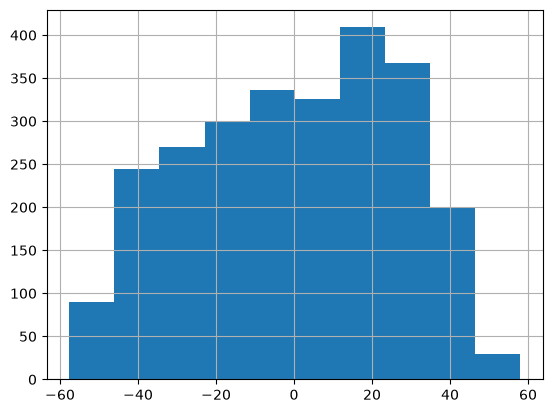

In [5]:
(children["StandingHeightCm"] - children["StandingHeightCm"].mean()).hist()

<Axes: >

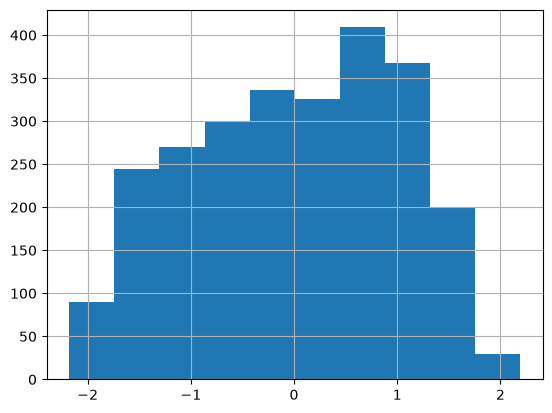

In [6]:
((children["StandingHeightCm"] - children["StandingHeightCm"].mean())/children["StandingHeightCm"].std()).hist()

Assignment 3 Question 2b

array([[<Axes: title={'center': 'StandingHeightCm'}>,
        <Axes: title={'center': 'AgeInYearsAtScreening'}>]], dtype=object)

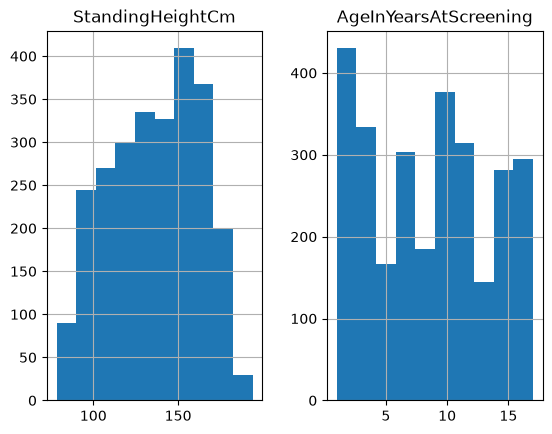

In [7]:
children[["StandingHeightCm","AgeInYearsAtScreening"]].hist()

array([[<Axes: title={'center': 'StandingHeightCm'}>,
        <Axes: title={'center': 'AgeInYearsAtScreening'}>]], dtype=object)

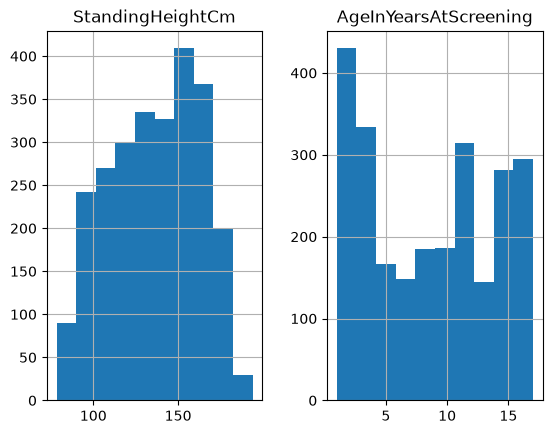

In [8]:
children[["StandingHeightCm","AgeInYearsAtScreening"]].replace([7,9,77,99,777,999,7777,9999], pd.NA).astype("Float64").hist()

Assignment 3 Question 2c

In [9]:
children["AgeInYearsAtScreening"].describe()


count    2833.000000
mean        8.513590
std         4.905092
min         1.000000
25%         4.000000
50%         8.000000
75%        13.000000
max        17.000000
Name: AgeInYearsAtScreening, dtype: float64

In [10]:
children["AgeInYearsAtScreening"].dropna().describe()

count    2833.000000
mean        8.513590
std         4.905092
min         1.000000
25%         4.000000
50%         8.000000
75%        13.000000
max        17.000000
Name: AgeInYearsAtScreening, dtype: float64

Assignment 3 Question 2d:

<Axes: xlabel='StandingHeightCm', ylabel='BodyMassIndexKgm2'>

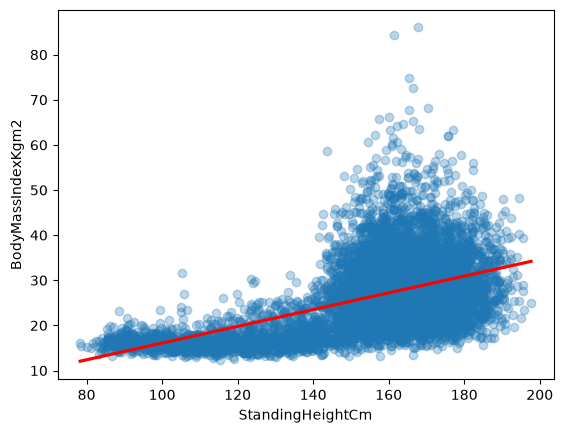

In [11]:
import seaborn as sns
import pingouin as pg
pg.linear_regression(nhanes["StandingHeightCm"], nhanes["BodyMassIndexKgm2"],remove_na=True)
sns.regplot(data=nhanes,x="StandingHeightCm", y="BodyMassIndexKgm2",scatter_kws={"color": "C0", "alpha": 0.3},line_kws={"color": "red"})

In [12]:
import seaborn as sns
import pingouin as pg
pg.linear_regression(nhanes["StandingHeightCm"], nhanes["BodyMassIndexKgm2"],remove_na=True)

,names,coef,se,T,pval,r2,adj_r2,CI2.5,CI97.5
0,Intercept,-2.443957,0.568574,-4.298396,0.000017,0.249317,0.249223,-3.558511,-1.329404
1,StandingHeightCm,0.185338,0.003595,51.555402,0.000000,0.249317,0.249223,0.178291,0.192385


Assignment 3 Question 3

In [ ]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [ ]:
# reading data 
import pandas as pd # import other packages if errors messages tell you
nhanes=pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")

/tmp/ipykernel_1446/823204058.py:2: DtypeWarning: Columns (141: ServedActiveDutyInUsArmedForces) have mixed types. Specify dtype option on import or set low_memory=False.
  nhanes=pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")


In [ ]:
# selecting children
children = nhanes[nhanes["AgeInYearsAtScreening"] < 18]

In [6]:
children["Gender_code"] = (children["Gender"].astype(str).str.lower().isin(["male", "1"])).astype(int)
children  = children[["StandingHeightCm", "AgeInYearsAtScreening", "Gender_code"]].dropna()

/tmp/ipykernel_1446/2276374121.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  children["Gender_code"] = (children["Gender"].astype(str).str.lower().isin(["male", "1"])).astype(int)


In [7]:
m_age = LinearRegression(fit_intercept=False).fit(children[["AgeInYearsAtScreening"]],children["StandingHeightCm"])
m_age_const = LinearRegression().fit(children[["AgeInYearsAtScreening"]], children["StandingHeightCm"])

In [8]:
m_full = LinearRegression().fit(children[["AgeInYearsAtScreening", "Gender_code"]],children["StandingHeightCm"])
children = children.sort_values("AgeInYearsAtScreening")

In [9]:
children["pred_age"] = m_age.predict(children[["AgeInYearsAtScreening"]])
children["pred_age_const"] = m_age_const.predict(children[["AgeInYearsAtScreening"]])
children["pred_full"] = m_full.predict(children[["AgeInYearsAtScreening", "Gender_code"]])

In [10]:
children["Age_Gender"] = (children["AgeInYearsAtScreening"] * children["Gender_code"])

In [11]:
m_interaction = LinearRegression().fit(children[["AgeInYearsAtScreening","Gender_code","Age_Gender"]],children["StandingHeightCm"])

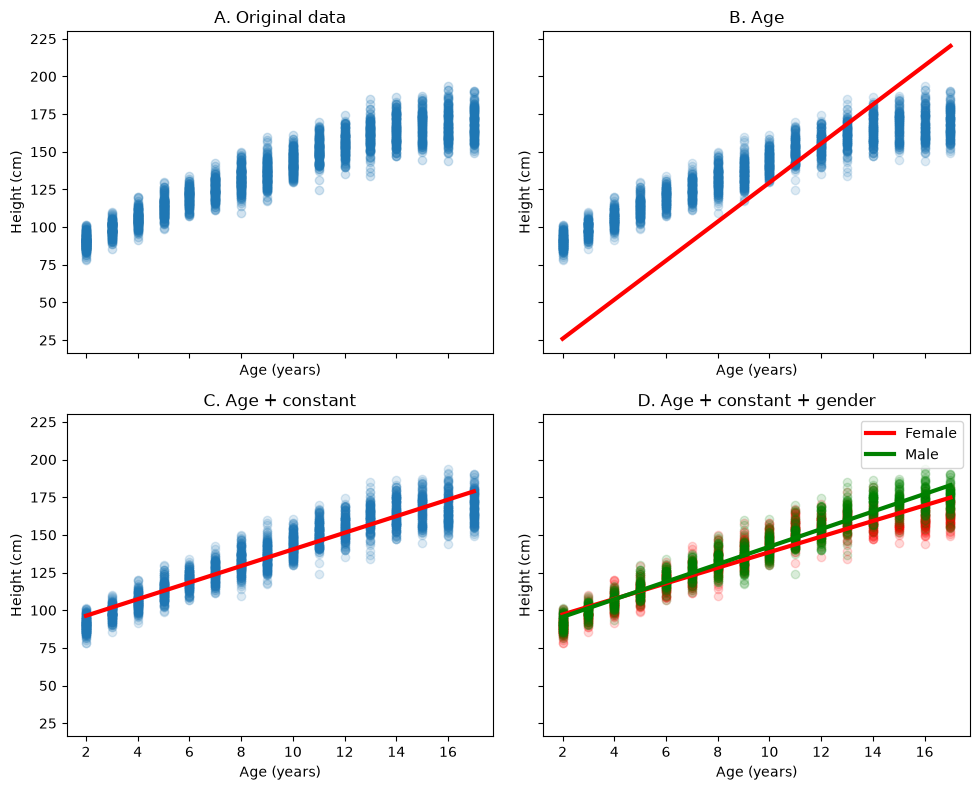

In [13]:
# code from class3.ipynb 
children["pred_interaction"] = m_interaction.predict(children[["AgeInYearsAtScreening","Gender_code","Age_Gender"]])
fig, ax = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

# A: Original data
ax[0,0].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.2)
ax[0,0].set_title("A. Original data")

# B: Age only
ax[0,1].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.15)
ax[0,1].plot(children["AgeInYearsAtScreening"], children["pred_age"], color="red", lw=3)
ax[0,1].set_title("B. Age")

# C: Age + constant
ax[1,0].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.15)
ax[1,0].plot(children["AgeInYearsAtScreening"], children["pred_age_const"], color="red", lw=3)
ax[1,0].set_title("C. Age + constant")

# D: Age + constant + gender
for g, color, label in [(0, "red", "Female"),(1, "green", "Male")]:
    tmp = children[children["Gender_code"] == g].sort_values("AgeInYearsAtScreening")
    ax[1,1].scatter(tmp["AgeInYearsAtScreening"],tmp["StandingHeightCm"],alpha=.15,color=color)
    ax[1,1].plot(tmp["AgeInYearsAtScreening"],tmp["pred_interaction"],color=color,lw=3,label=label)
ax[1,1].legend()
ax[1,1].set_title("D. Age + constant + gender")

for a in ax.ravel():
    a.set_xlabel("Age (years)")
    a.set_ylabel("Height (cm)")
plt.tight_layout()
plt.show()